---
title: The diurnal cycle of summer rainfall over the United States (GPM IMERG)
author: Harsha R. Hampapura
date: 2026-10-23
---

## The diurnal cycle of summer rainfall over the United States

[GPM IMERG Final (half-hourly)](https://gdex.ucar.edu/datasets/d731000/) estimates
precipitation over the globe at 0.1° resolution **every 30 minutes**, from June 2000 to
October 2025. It comes from **GPM**, the
[Global Precipitation Measurement](https://climatedataguide.ucar.edu/climate-data/gpm-global-precipitation-measurement-mission)
mission, and **IMERG** (*Integrated Multi-satellitE Retrievals for GPM*), which blends
microwave and infrared satellite observations into a single precipitation field.

Half-hourly data can show something monthly and daily averages cannot: **when during the
day it rains**. In summer, rainfall over much of the United States follows a daily rhythm
set by the Sun — afternoon thunderstorms over the Southeast and the mountains, sea-breeze
storms over Florida, and a night-time maximum over the Great Plains, where storm systems
that form over the Rockies in the afternoon travel east overnight.

In this notebook we

1. select the summer months (June–August) of **2023–2025** over the contiguous US,
2. average each of the **48 half-hour slots** of the day across those ~275 days to build a
   mean summer day of rainfall, then
3. animate the 48 frames to watch rainfall rise and fall through the day.

For the long-term spatial picture, see the companion
[monthly](./imerg_monthly_itcz.ipynb) and [daily](./imerg_daily.ipynb) IMERG notebooks.

:::{seealso} Original visualization
This workflow reproduces **"Precipitation Diurnal Cycles"** — NASA Goddard Space Flight
Center Scientific Visualization Studio, [SVS #13346](https://svs.gsfc.nasa.gov/13346/)
(released 15 October 2019). Visualizers: Jackson Boon Sze Tan (USRA) and Alex Kekesi
(GST, Inc.); producers: Ryan Fitzgibbons and Joy Ng (USRA). *Credit: NASA's Goddard Space
Flight Center.* Our version uses the GDEX IMERG half-hourly record for June–August
2023–2025, rather than the ~20-year average in the original.
:::

In [1]:
import os
import shutil
import datetime
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Dask
from dask_jobqueue import PBSCluster
from dask.distributed import Client, LocalCluster

## Open the dataset

IMERG half-hourly is distributed as one NetCDF granule per half hour — more than 440,000
files. GDEX adds **kerchunk** references so a single `xr.open_dataset(..., engine="kerchunk")`
call exposes the whole record as one virtual `xarray.Dataset`. Because the record is so long,
GDEX publishes **one reference per variable**, stored as [Parquet](https://fsspec.github.io/kerchunk/spec.html#parquet-references)
so it is read lazily; we only need `precipitation`.

:::{important} No edits needed
The cell below **automatically selects the data path** — the POSIX reference where
`/gdex/data` is mounted (NCAR HPC), otherwise the OSDF reference over the network. **You
don't need to change anything.**
:::

In [2]:
# POSIX reference where the GDEX data mount is present (NCAR HPC), otherwise the
# OSDF-routed reference over the network.
posix_ref = "/gdex/data/d731000/kerchunk/precipitation_GPM_3IMERGHH_v07-remote-https.parq"
osdf_ref  = "https://data.gdex.ucar.edu/d731000/kerchunk/precipitation_GPM_3IMERGHH_v07-remote-osdf.parq"

kerchunk_ref = posix_ref if os.path.exists(posix_ref) else osdf_ref
print(f"Access: {'POSIX mount' if kerchunk_ref == posix_ref else 'OSDF (remote)'}")
print(kerchunk_ref)

Access: POSIX mount
/gdex/data/d731000/kerchunk/precipitation_GPM_3IMERGHH_v07-remote-https.parq


## Set up a Dask cluster

Building the composite reads every half-hourly field for three summers over the US, so we
spread the work across a [Dask](https://docs.dask.org/) cluster. As in the other GDEX
examples, the cluster is chosen automatically:

- **Casper / Derecho** (a PBS scheduler is present) → a `PBSCluster` of batch workers.
- **Laptop / CIRRUS Binder** (no PBS) → a `LocalCluster` on the local cores.

In [3]:
N_WORKERS = 10

def get_pbs_cluster(n_workers=N_WORKERS):
    """PBSCluster on NCAR HPC (Casper/Derecho)."""
    scratch = f"/glade/derecho/scratch/{os.environ.get('USER', '')}"
    cluster = PBSCluster(
        job_name        = "imerg-halfhourly",
        cores           = 1,
        memory          = "8GiB",
        processes       = 1,
        local_directory = f"{scratch}/dask/spill/",
        log_directory   = f"{scratch}/dask/logs/",
        resource_spec   = "select=1:ncpus=1:mem=8GB",
        queue           = "casper",
        walltime        = "2:00:00",
        interface       = "ext",
    )
    cluster.scale(n_workers)
    return cluster


def get_local_cluster():
    """LocalCluster for a laptop or a CIRRUS Binder pod (no PBS scheduler)."""
    return LocalCluster()

:::{important} No edits needed
This cell **automatically selects the right Dask cluster** — a PBS cluster on NCAR HPC
(Casper/Derecho), or a `LocalCluster` on CIRRUS Binder or a laptop. **You don't need to
change anything;** the helper functions above show how each is built.
:::

In [4]:
on_hpc  = bool(shutil.which("qsub"))
cluster = get_pbs_cluster() if on_hpc else get_local_cluster()
client  = Client(cluster)
if on_hpc:
    client.wait_for_workers(n_workers=N_WORKERS)

print(f"Detected {'NCAR HPC -> PBSCluster' if on_hpc else 'no PBS -> LocalCluster'}")
cluster

/glade/u/home/harshah/.conda/envs/zarr3/lib/python3.11/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 39211 instead
  warnings.warn(


Detected NCAR HPC -> PBSCluster


PBSCluster(f4bc9915, 'tcp://128.117.208.174:39343', workers=10, threads=10, memory=80.00 GiB)

## Subset to summers over the contiguous US

We keep a box around the contiguous US (125°W–66°W, 24°N–50°N) and the June–August (JJA)
period of 2023, 2024 and 2025 — 92 days × 48 half-hours × 3 summers = 13,248 fields.

:::{tip} Why open with large time chunks?
Each native chunk in the reference holds just **one half-hour** of data. Opening with the
default chunking would give Dask hundreds of thousands of tiny tasks, and the task graph
alone can overwhelm the scheduler (which runs in this notebook's kernel). Asking for chunks
of 480 time steps (10 days) keeps the graph small while each chunk still fits comfortably
in a worker's memory.
:::

In [5]:
ds = xr.open_dataset(kerchunk_ref, engine="kerchunk",
                     open_dataset_options={"chunks": None},                 # plain lazy arrays, no hidden Dask layer
                     drop_variables=["lat_bnds", "lon_bnds", "time_bnds"])
precip = ds["precipitation"]                                                 # (time, lon, lat), mm/hr

# Contiguous US, June-August of 2023-2025; chunk only the selection (96 = 2 days)
conus = dict(lon=slice(-125, -66), lat=slice(24, 50))
summers = [precip.sel(time=slice(f"{y}-06-01", f"{y}-08-31"), **conus).chunk({"time": 96})
           for y in (2023, 2024, 2025)]
precip_jja = xr.concat(summers, dim="time")
precip_jja = precip_jja.where(precip_jja >= 0)                               # mask fill values

print("half-hourly steps:", precip_jja.sizes["time"],
      "| dask chunks:", precip_jja.data.npartitions,
      "| tasks in graph:", len(precip_jja.__dask_graph__()))
precip_jja

half-hourly steps: 13248 | dask chunks: 138 | tasks in graph: 555


<xarray.DataArray 'precipitation' (time: 13248, lon: 590, lat: 260)> Size: 8GB
dask.array<where, shape=(13248, 590, 260), dtype=float32, chunksize=(96, 590, 260), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 106kB 2023-06-01 00:00:00 ... 2025-08-31 23:30:00
  * lon      (lon) float32 2kB -124.9 -124.8 -124.8 ... -66.25 -66.15 -66.05
  * lat      (lat) float32 1kB 24.05 24.15 24.25 24.35 ... 49.75 49.85 49.95
Attributes:
    CodeMissingValue:  -9999.9
    DimensionNames:    time,lon,lat
    LongName:          \nComplete merged microwave-infrared (gauge-adjusted)\...
    Units:             mm/hr
    units:             mm/hr

## Build the mean summer day

Each half-hourly field is labeled with its **slot of the day** — 0 for 00:00 UTC, 1 for
00:30, … 47 for 23:30 — and all 276 summer days are averaged slot by slot. The result is
48 maps: the average rain rate at each half hour of a typical summer day. Times are in
**UTC**; the contiguous US is 4–7 hours behind (e.g. 18:00 UTC is 1 p.m. Central Daylight Time).

In [7]:
%%time
# Sanity checks: whole days only, and slots run 0..47 in order every day
t = precip_jja["time"]
nslot = 48
assert precip_jja.sizes["time"] % nslot == 0
slots = (t.dt.hour * 2 + t.dt.minute // 30).values
assert (slots == np.tile(np.arange(nslot), len(slots) // nslot)).all()

# Fold time -> (day, halfhour) and average over days
days = (precip_jja.coarsen(time=nslot)
                  .construct(time=("day", "halfhour"))
                  .drop_vars("time"))                      # (day, halfhour, lon, lat)
diurnal = days.mean("day").transpose("halfhour", "lat", "lon").compute()
diurnal = diurnal.assign_coords(halfhour=np.arange(nslot))
diurnal.attrs["units"] = "mm/hr"
print("shape:", diurnal.shape,
      "| range:", round(float(diurnal.min()), 3), "-", round(float(diurnal.max()), 3), "mm/hr")
diurnal

shape: (48, 260, 590) | range: 0.0 - 1.294 mm/hr
CPU times: user 4.03 s, sys: 586 ms, total: 4.61 s
Wall time: 1min 22s


<xarray.DataArray 'precipitation' (halfhour: 48, lat: 260, lon: 590)> Size: 29MB
array([[[3.62318824e-05, 3.62318824e-05, 0.00000000e+00, ...,
         6.08333312e-02, 6.63043484e-02, 6.28260896e-02],
        [7.24637648e-05, 1.08695647e-04, 7.24637648e-05, ...,
         7.31884018e-02, 6.23550676e-02, 4.46376838e-02],
        [3.62318824e-05, 1.08695647e-04, 1.73913036e-03, ...,
         7.04347864e-02, 7.36594200e-02, 3.89130414e-02],
        ...,
        [5.84782586e-02, 5.67391329e-02, 5.74637651e-02, ...,
         1.62028983e-01, 2.03405783e-01, 1.79782599e-01],
        [8.13768059e-02, 7.05797076e-02, 5.88768050e-02, ...,
         2.30181158e-01, 2.19057947e-01, 2.22753614e-01],
        [8.14130455e-02, 8.65217373e-02, 7.48913065e-02, ...,
         2.37029001e-01, 1.97282612e-01, 1.65833339e-01]],

       [[3.62318824e-05, 0.00000000e+00, 1.08695647e-04, ...,
         8.31159428e-02, 8.39855075e-02, 8.70289803e-02],
        [3.62318824e-05, 0.00000000e+00, 7.24637648e-05, ...,
         7.09420219e-02, 6.43115863e-02, 5.20652197e-02],
        [1.08695647e-04, 7.24637648e-05, 1.73913036e-03, ...,
         8.10507238e-02, 6.28260896e-02, 4.51449305e-02],
...
        [3.27898562e-02, 6.32246360e-02, 5.69927506e-02, ...,
         1.22681163e-01, 1.55471012e-01, 2.04021737e-01],
        [7.18840584e-02, 8.84420201e-02, 7.21014440e-02, ...,
         1.25615939e-01, 1.33695662e-01, 1.67753607e-01],
        [8.16304311e-02, 7.70289898e-02, 7.79347792e-02, ...,
         1.27681151e-01, 1.68043464e-01, 1.71014503e-01]],

       [[2.17391280e-04, 1.08695647e-04, 7.24637648e-05, ...,
         7.75362328e-02, 9.54347849e-02, 9.45652127e-02],
        [7.24637648e-05, 3.62318824e-05, 7.24637648e-05, ...,
         7.44202882e-02, 8.38768110e-02, 9.96739045e-02],
        [7.24637648e-05, 3.62318824e-05, 3.62318824e-05, ...,
         7.06521720e-02, 6.55072480e-02, 5.93478233e-02],
        ...,
        [3.83333340e-02, 4.24275361e-02, 5.37681170e-02, ...,
         1.34601459e-01, 1.64239123e-01, 1.61956504e-01],
        [6.65941983e-02, 6.15217388e-02, 8.50724578e-02, ...,
         1.16702892e-01, 1.29673898e-01, 1.48405805e-01],
        [8.30797106e-02, 7.60507137e-02, 6.88043460e-02, ...,
         1.16702892e-01, 1.93913043e-01, 1.82789862e-01]]], dtype=float32)
Coordinates:
  * halfhour  (halfhour) int64 384B 0 1 2 3 4 5 6 7 ... 40 41 42 43 44 45 46 47
  * lat       (lat) float32 1kB 24.05 24.15 24.25 24.35 ... 49.75 49.85 49.95
  * lon       (lon) float32 2kB -124.9 -124.8 -124.8 ... -66.25 -66.15 -66.05
Attributes:
    CodeMissingValue:  -9999.9
    DimensionNames:    time,lon,lat
    LongName:          \nComplete merged microwave-infrared (gauge-adjusted)\...
    Units:             mm/hr
    units:             mm/hr

## Animate the mean summer day

We play the 48 half-hourly maps from midnight to midnight **Central Daylight Time**
(CDT = UTC − 5 h), so the animation reads like a single summer day over the middle of the
country. Each frame is labeled in both UTC and CDT. Look for:

- afternoon thunderstorms building over Florida, the Southeast and the Rocky Mountains;
- rain over the Great Plains that peaks **overnight**, as storm systems that form over the
  Rockies in the afternoon travel east after dark.

As in the [daily notebook](./imerg_daily.ipynb), cooler colors are drier and warmer colors
are wetter (mm/hr).

CPU times: user 12.9 s, sys: 1.03 s, total: 14 s
Wall time: 13.7 s


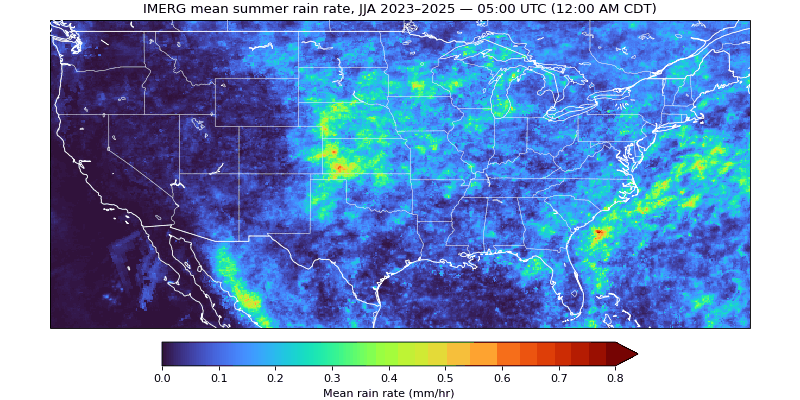

In [8]:
%%time
# Frame order: midnight -> midnight CDT (slot 10 = 05:00 UTC = 00:00 CDT)
start = 10
order = [(start + k) % 48 for k in range(48)]

def clock(slot):
    """Label a half-hour slot of the UTC day as 'HH:MM UTC (h:MM AM/PM CDT)'."""
    utc = datetime.datetime(2024, 7, 1) + datetime.timedelta(minutes=30 * int(slot))
    cdt = utc - datetime.timedelta(hours=5)
    return f"{utc:%H:%M} UTC ({cdt:%-I:%M %p} CDT)"

# Flat map whose extent matches the data box exactly, so the field fills the frame
pc = ccrs.PlateCarree()
extent = [float(diurnal.lon.min()), float(diurnal.lon.max()),
          float(diurnal.lat.min()), float(diurnal.lat.max())]
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={"projection": pc},
                       constrained_layout=True)
ax.set_extent(extent, crs=pc)

mesh = ax.pcolormesh(diurnal["lon"], diurnal["lat"], diurnal.isel(halfhour=order[0]),
                     transform=pc, cmap="turbo", vmin=0, vmax=0.8,
                     shading="auto", rasterized=True)

# Crisp white outlines drawn on top of the data (visible on dark and bright colors)
lines = dict(facecolor="none", edgecolor="white", zorder=3)
ax.add_feature(cfeature.STATES.with_scale("50m"),  linewidth=0.4, alpha=0.7, **lines)
ax.add_feature(cfeature.LAKES.with_scale("50m"),   linewidth=0.5, **lines)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.8, **lines)
ax.coastlines("50m", color="white", linewidth=0.8, zorder=3)

cb = plt.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.6, pad=0.04, extend="max")
cb.set_label("Mean rain rate (mm/hr)")
title = ax.set_title("")

def update(i):
    slot = order[i]
    mesh.set_array(diurnal.isel(halfhour=slot).values.ravel())
    title.set_text(f"IMERG mean summer rain rate, JJA 2023–2025 — {clock(slot)}")
    return mesh, title

anim = animation.FuncAnimation(fig, update, frames=48, interval=150)
anim.save("imerg_halfhourly_diurnal.gif", writer=animation.PillowWriter(fps=6), dpi=80)
plt.close(fig)

from IPython.display import Image
Image("imerg_halfhourly_diurnal.gif")

## Citation

If you use this data or workflow, please cite:

**Data (GDEX copy used in this notebook)**
Huffman, G. J., E. F. Stocker, D. T. Bolvin, E. J. Nelkin, and J. Tan. 2024, updated
irregularly. GPM IMERG Final Precipitation L3 Half Hourly 0.1 degree x 0.1 degree V07.
NSF National Center for Atmospheric Research. <https://doi.org/10.5065/SRTD-0R12>.
Accessed† dd mmm yyyy.

† Replace *dd mmm yyyy* with the date you last accessed the data (e.g. 5 Aug 2011).

**Original data product**
Huffman, G. J., E. F. Stocker, D. T. Bolvin, E. J. Nelkin, and J. Tan, 2023: GPM IMERG
Final Precipitation L3 Half Hourly 0.1 degree x 0.1 degree V07. NASA Goddard Earth Sciences
Data and Information Services Center (GES DISC). <https://doi.org/10.5067/GPM/IMERG/3B-HH/07>

**Visualization reproduced here**
NASA's Goddard Space Flight Center Scientific Visualization Studio, 2019: Precipitation
Diurnal Cycles. SVS #13346. Visualizers: J. B. S. Tan and A. Kekesi; producers:
R. Fitzgibbons and J. Ng. <https://svs.gsfc.nasa.gov/13346/>

**This notebook**
NCAR GDEX Examples (all versions). <https://doi.org/10.5281/zenodo.20330479>

:::{seealso} Further reading
- [IMERG and the GPM mission](https://climatedataguide.ucar.edu/climate-data/gpm-global-precipitation-measurement-mission) (NCAR Climate Data Guide)
- [GDEX dataset d731000](https://gdex.ucar.edu/datasets/d731000/) (documentation and other access methods)
:::